# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : *(Rifqi Haikal Abimanyu)*
- NIM   : 241011402298
- Kelas : *(Reg B)*

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# Import library yang diizinkan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

RANDOM_STATE = 98  # Dua digit terakhir NIM: 98

In [2]:
def train_test_split(X, y, test_size=0.25, random_state=None):
    """Membagi pasangan X dan y secara acak tanpa scikit-learn."""
    X = np.asarray(X)
    y = np.asarray(y)
    if len(X) != len(y):
        raise ValueError("X dan y harus memiliki jumlah baris yang sama.")
    if not 0 < test_size < 1:
        raise ValueError("test_size harus berada di antara 0 dan 1.")

    rng = np.random.default_rng(random_state)
    indices = rng.permutation(len(X))
    n_test = int(np.ceil(len(X) * test_size))
    test_indices = indices[:n_test]
    train_indices = indices[n_test:]
    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data iklan: 40
Shape X: (40, 1) | Shape y: (40,)


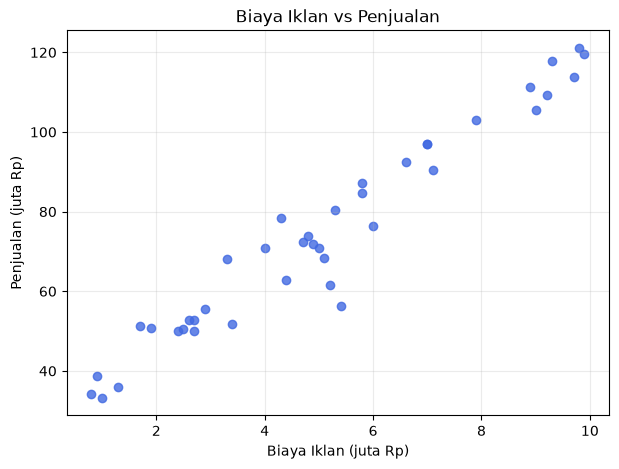

In [3]:
ads = pd.read_csv("Ads_Data.csv")
display(ads.head())
print(f"Jumlah baris data iklan: {len(ads)}")

X_ads = ads[["BiayaIklan"]].to_numpy(dtype=float)
y_ads = ads["Penjualan"].to_numpy(dtype=float)
print("Shape X:", X_ads.shape, "| Shape y:", y_ads.shape)

plt.figure(figsize=(7, 5))
plt.scatter(X_ads[:, 0], y_ads, color="royalblue", alpha=0.8)
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.25)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [5]:
class LinearRegression:
    """Regresi linear dengan solusi normal equation."""
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        X_with_intercept = np.c_[np.ones(X.shape[0]), X]
        theta = np.linalg.pinv(X_with_intercept.T @ X_with_intercept) @ X_with_intercept.T @ y
        self.intercept_ = float(theta[0])
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self.intercept_ + X @ self.coef_

linear_model = LinearRegression().fit(X_train, y_train)
print(f"Intercept (b): {linear_model.intercept_:.6f}")
print(f"Koefisien (m): {linear_model.coef_[0]:.6f}")
print(f"Persamaan: y_hat = {linear_model.intercept_:.4f} + {linear_model.coef_[0]:.4f} X")
print(f"Interpretasi: setiap kenaikan biaya iklan Rp1 juta diperkirakan mengubah penjualan sebesar {linear_model.coef_[0]:.3f} juta Rp.")

Intercept (b): 27.447001
Koefisien (m): 9.280818
Persamaan: y_hat = 27.4470 + 9.2808 X
Interpretasi: setiap kenaikan biaya iklan Rp1 juta diperkirakan mengubah penjualan sebesar 9.281 juta Rp.


**Jawaban A3 (interpretasi):** Koefisien kemiringan pada output menunjukkan perubahan rata-rata penjualan (juta rupiah) untuk setiap kenaikan biaya iklan sebesar Rp1 juta. Karena koefisiennya positif, model memperkirakan hubungan searah; ini menunjukkan asosiasi pada data, bukan bukti bahwa iklan sendirian menyebabkan kenaikan penjualan.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [6]:
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    errors = y_true - y_pred
    mae = np.mean(np.abs(errors))
    mse = np.mean(errors ** 2)
    rmse = np.sqrt(mse)
    ss_res = np.sum(errors ** 2)
    ss_total = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - ss_res / ss_total if ss_total != 0 else np.nan
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

train_metrics = regression_metrics(y_train, linear_model.predict(X_train))
test_metrics = regression_metrics(y_test, linear_model.predict(X_test))
regression_results = pd.DataFrame([train_metrics, test_metrics], index=["Training", "Testing"])
display(regression_results.round(4))
print(f"RMSE testing {test_metrics['RMSE']:.3f} juta Rp berarti besarnya kesalahan prediksi tipikal sekitar itu.")
print(f"R2 testing {test_metrics['R2']:.3f} menunjukkan proporsi variasi penjualan yang dijelaskan model pada data testing.")

,MAE,MSE,RMSE,R2
Training,4.4290,37.7538,6.1444,0.9315
Testing,4.5446,30.1711,5.4928,0.9688


RMSE testing 5.493 juta Rp berarti besarnya kesalahan prediksi tipikal sekitar itu.
R2 testing 0.969 menunjukkan proporsi variasi penjualan yang dijelaskan model pada data testing.


**Jawaban A4 (analisis):** RMSE memiliki satuan yang sama dengan target, yaitu juta rupiah, sehingga dapat dibaca sebagai besar kesalahan prediksi tipikal; semakin kecil nilainya, semakin dekat prediksi ke data. R? menunjukkan seberapa besar variasi penjualan yang diterangkan model; nilai mendekati 1 lebih baik, sedangkan nilai negatif berarti model lebih buruk daripada tebakan rata-rata data testing. Gunakan angka pada tabel testing untuk menilai kualitas generalisasi, lalu bandingkan dengan training: selisih yang besar dapat menjadi tanda model kurang stabil.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

,Learning rate,Intercept,Koefisien,MSE akhir,Status
0,0.001,2.347690e+01,9.922641e+00,40.749980,Berjalan
1,0.020,2.744700e+01,9.280818e+00,37.753849,Berjalan
2,0.100,3.436739e+152,2.125849e+153,inf,Divergen


Normal equation: intercept=27.447001, koefisien=9.280818


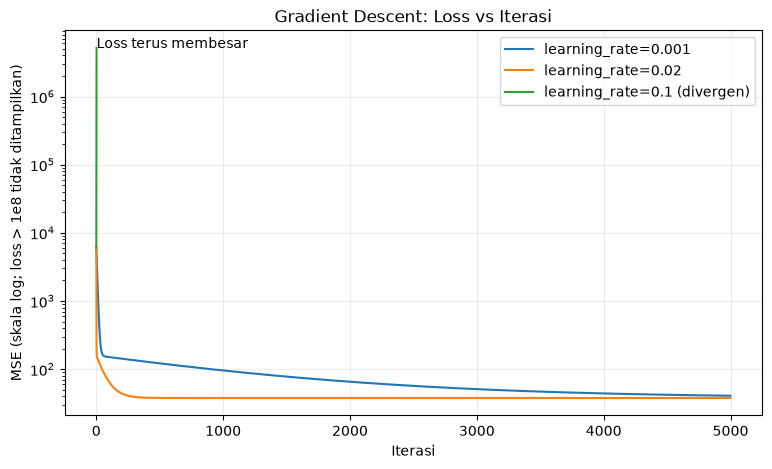

In [7]:
class LinearRegressionGD:
    """Gradient descent batch untuk regresi linear; mencatat MSE setiap iterasi."""
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        X_b = np.c_[np.ones(X.shape[0]), X]
        theta = np.zeros(X_b.shape[1])
        self.loss_history_ = []
        self.diverged_ = False
        with np.errstate(over="ignore", invalid="ignore"):
            for _ in range(self.n_iterations):
                errors = X_b @ theta - y
                loss = np.mean(errors ** 2)
                if not np.isfinite(loss):
                    self.diverged_ = True
                    self.loss_history_.extend([np.inf] * (self.n_iterations - len(self.loss_history_)))
                    break
                self.loss_history_.append(float(loss))
                gradient = (2 / len(y)) * (X_b.T @ errors)
                next_theta = theta - self.learning_rate * gradient
                if not np.all(np.isfinite(next_theta)):
                    self.diverged_ = True
                    self.loss_history_.extend([np.inf] * (self.n_iterations - len(self.loss_history_)))
                    break
                theta = next_theta
        self.intercept_ = float(theta[0])
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self.intercept_ + X @ self.coef_

learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
comparison_rows = []
for lr in learning_rates:
    model = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    gd_models[lr] = model
    comparison_rows.append({
        "Learning rate": lr,
        "Intercept": model.intercept_,
        "Koefisien": model.coef_[0],
        "MSE akhir": model.loss_history_[-1],
        "Status": "Divergen" if model.diverged_ else "Berjalan"
    })
display(pd.DataFrame(comparison_rows).round(6))
print(f"Normal equation: intercept={linear_model.intercept_:.6f}, koefisien={linear_model.coef_[0]:.6f}")

plt.figure(figsize=(9, 5))
for lr, model in gd_models.items():
    losses = np.asarray(model.loss_history_)
    finite = np.isfinite(losses) & (losses > 0)
    visible = finite & (losses < 1e8)
    label = f"learning_rate={lr}" + (" (divergen)" if model.diverged_ else "")
    plt.plot(np.flatnonzero(visible), losses[visible], label=label)
    if model.diverged_ and np.any(visible):
        last = np.flatnonzero(visible)[-1]
        plt.annotate("Loss terus membesar", (last, losses[visible][-1]))
plt.yscale("log")
plt.xlabel("Iterasi")
plt.ylabel("MSE (skala log; loss > 1e8 tidak ditampilkan)")
plt.title("Gradient Descent: Loss vs Iterasi")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

**Jawaban A5 (analisis):** Pada learning rate 0,001, loss turun tetapi setelah 5.000 iterasi masih sekitar 40,75 dan parameternya belum mendekati solusi normal equation; laju ini terlalu lambat. Learning rate 0,02 menghasilkan parameter yang praktis sama dengan normal equation dan MSE sekitar 37,75, sehingga paling sesuai di antara tiga percobaan. Learning rate 0,1 membuat loss membesar hingga tak hingga dan parameternya meledak, yaitu divergen karena langkah pembaruan terlalu besar untuk fitur biaya iklan yang tidak dinormalisasi.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

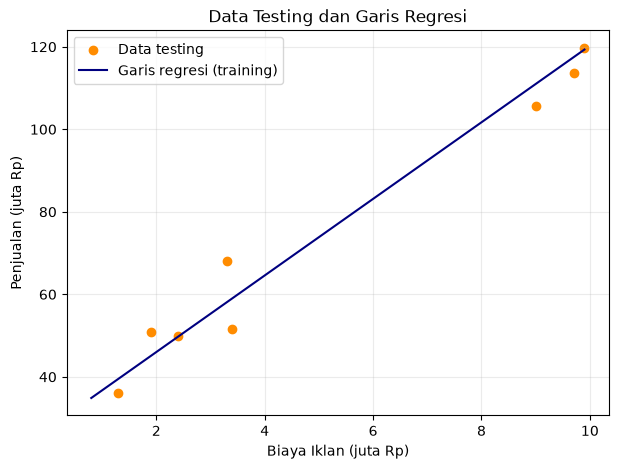

,BiayaIklan (juta Rp),PrediksiPenjualan (juta Rp)
0,4.5,69.211
1,7.0,92.413
2,12.0,138.817


In [8]:
# Scatter data testing dan garis dari model normal equation
x_line = np.linspace(X_ads.min(), X_ads.max(), 200).reshape(-1, 1)
plt.figure(figsize=(7, 5))
plt.scatter(X_test[:, 0], y_test, label="Data testing", color="darkorange")
plt.plot(x_line[:, 0], linear_model.predict(x_line), label="Garis regresi (training)", color="navy")
plt.title("Data Testing dan Garis Regresi")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

advertising_costs = np.array([[4.5], [7.0], [12.0]])
predicted_sales = linear_model.predict(advertising_costs)
prediction_table = pd.DataFrame({
    "BiayaIklan (juta Rp)": advertising_costs[:, 0],
    "PrediksiPenjualan (juta Rp)": predicted_sales
})
display(prediction_table.round(3))

**Jawaban A6 (analisis):** Prediksi pada 4,5 dan 7 juta lebih layak dipercaya karena berada di dalam rentang biaya iklan yang diamati; tetap saja, hasilnya bergantung pada asumsi hubungan linear dan faktor lain yang tidak dimodelkan. Nilai 12 juta berada di luar rentang data sehingga merupakan ekstrapolasi. Pola hubungan dapat berubah di luar data yang tersedia, jadi prediksi 12 juta jauh lebih tidak pasti dan sebaiknya tidak dijadikan dasar keputusan tanpa data tambahan.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah kelas Spam (1) dan Bukan Spam (0):


,Jumlah
Spam,
Bukan Spam,35
Spam,25


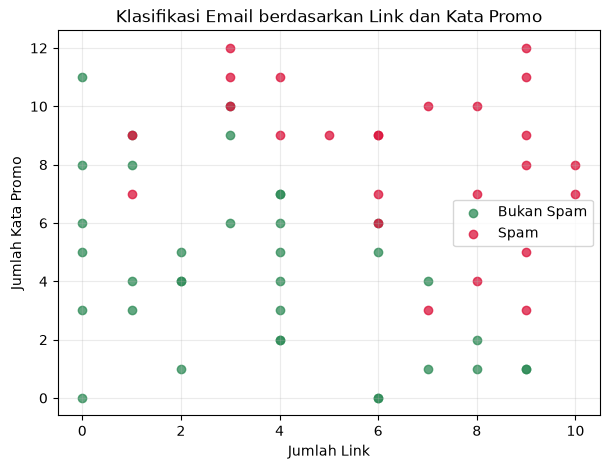

In [9]:
emails = pd.read_csv("Email_Data.csv")
display(emails.head())
print("Jumlah kelas Spam (1) dan Bukan Spam (0):")
display(emails["Spam"].value_counts().sort_index().rename(index={0: "Bukan Spam", 1: "Spam"}).to_frame("Jumlah"))

X_email = emails[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
y_email = emails["Spam"].to_numpy(dtype=int)

plt.figure(figsize=(7, 5))
for label, name, color in [(0, "Bukan Spam", "seagreen"), (1, "Spam", "crimson")]:
    mask = y_email == label
    plt.scatter(X_email[mask, 0], X_email[mask, 1], label=name, color=color, alpha=0.75)
plt.title("Klasifikasi Email berdasarkan Link dan Kata Promo")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

X_train: (45, 2) | X_test: (15, 2)
Intercept (b): -9.373398
Koefisien: [0.81382939 0.85773365]
P(Spam) = sigmoid(-9.3734 + 0.8138 * JumlahLink + 0.8577 * KataPromo)


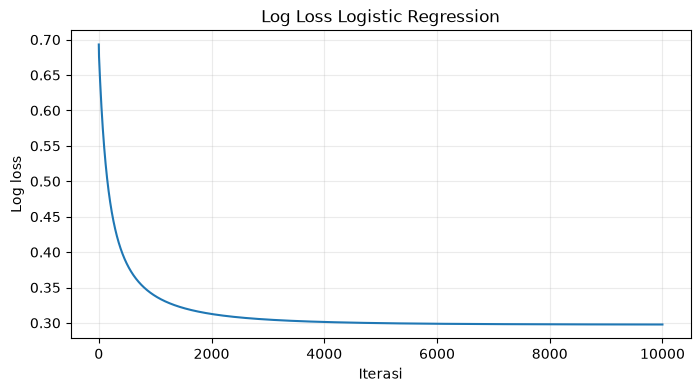

Log loss awal=0.6931; akhir=0.2978


In [10]:
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

class LogisticRegression:
    """Regresi logistik biner dengan batch gradient descent."""
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    @staticmethod
    def _sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        X_b = np.c_[np.ones(X.shape[0]), X]
        theta = np.zeros(X_b.shape[1])
        self.loss_history_ = []
        eps = 1e-15
        for _ in range(self.n_iterations):
            probabilities = self._sigmoid(X_b @ theta)
            loss = -np.mean(y * np.log(probabilities + eps) + (1 - y) * np.log(1 - probabilities + eps))
            self.loss_history_.append(float(loss))
            gradient = X_b.T @ (probabilities - y) / len(y)
            theta -= self.learning_rate * gradient
        self.intercept_ = float(theta[0])
        self.coef_ = theta[1:]
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        p_spam = self._sigmoid(self.intercept_ + X @ self.coef_)
        return np.column_stack((1 - p_spam, p_spam))

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

logistic_model = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(X_train_email, y_train_email)
print("X_train:", X_train_email.shape, "| X_test:", X_test_email.shape)
print(f"Intercept (b): {logistic_model.intercept_:.6f}")
print("Koefisien:", logistic_model.coef_)
print(f"P(Spam) = sigmoid({logistic_model.intercept_:.4f} + {logistic_model.coef_[0]:.4f} * JumlahLink + {logistic_model.coef_[1]:.4f} * KataPromo)")

plt.figure(figsize=(8, 4))
plt.plot(logistic_model.loss_history_)
plt.xlabel("Iterasi")
plt.ylabel("Log loss")
plt.title("Log Loss Logistic Regression")
plt.grid(alpha=0.25)
plt.show()
print(f"Log loss awal={logistic_model.loss_history_[0]:.4f}; akhir={logistic_model.loss_history_[-1]:.4f}")

**Jawaban B2 (analisis):** Log loss turun dari 0,6931 menjadi 0,2978 setelah 10.000 iterasi, sehingga model belajar lebih baik daripada tebakan awal dan loss sudah jauh lebih rendah. Kedua koefisien positif, sehingga pada model ini kenaikan jumlah link atau kata promo meningkatkan skor/probabilitas spam ketika fitur lain tetap. Intercept dan koefisien adalah parameter skor linear, sedangkan sigmoid mengubah skor tersebut menjadi probabilitas antara 0 dan 1.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [11]:
def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=int).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=int).reshape(-1)
    return np.array([
        [np.sum((y_true == 0) & (y_pred == 0)), np.sum((y_true == 0) & (y_pred == 1))],
        [np.sum((y_true == 1) & (y_pred == 0)), np.sum((y_true == 1) & (y_pred == 1))]
    ])

def accuracy_score(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    return np.mean(y_true == y_pred)

def classification_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"Accuracy": accuracy_score(y_true, y_pred), "Precision": precision,
            "Recall": recall, "F1": f1, "TN": tn, "FP": fp, "FN": fn, "TP": tp}

pred_test_email = logistic_model.predict(X_test_email)
email_metrics = classification_metrics(y_test_email, pred_test_email)
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test_email, pred_test_email))
display(pd.DataFrame([email_metrics], index=["Testing"]).round(4))

Confusion matrix [[TN, FP], [FN, TP]]:
[[7 2]
 [0 6]]


,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
Testing,0.8667,0.75,1.0,0.8571,7,2,0,6


**Jawaban B3 (analisis):** FP adalah email bukan spam yang keliru ditandai sebagai spam; email penting dapat tersaring dan terlewat oleh pengguna. FN adalah email spam yang lolos ke kotak masuk. Untuk layanan email umum, FP sering lebih merugikan karena dapat menyembunyikan pesan sah yang penting, walaupun toleransi terhadap spam juga bergantung pada kebutuhan pengguna. Confusion matrix memperlihatkan jumlah masing-masing kesalahan pada data testing.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: -9.3734 + (0.8138) x1 + (0.8577) x2 = 0
x2 = -(-9.3734 + (0.8138) x1) / (0.8577)
Indeks data testing yang salah klasifikasi (posisi 0-based): [3, 7]


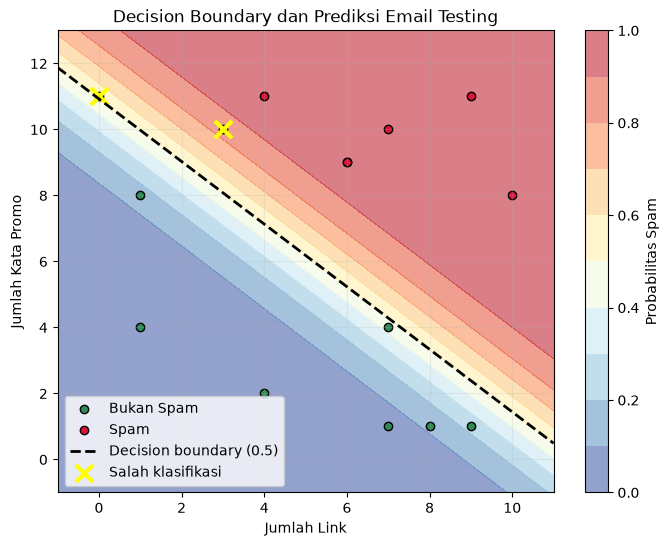

In [12]:
m1, m2 = logistic_model.coef_
b = logistic_model.intercept_
print(f"Decision boundary: {b:.4f} + ({m1:.4f}) x1 + ({m2:.4f}) x2 = 0")
if np.isclose(m2, 0):
    print("Koefisien x2 mendekati nol; garis tidak dapat dinyatakan sebagai x2 = -(b + m1*x1)/m2.")
else:
    print(f"x2 = -({b:.4f} + ({m1:.4f}) x1) / ({m2:.4f})")

x1_min, x1_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
x2_min, x2_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
grid_x1, grid_x2 = np.meshgrid(np.linspace(x1_min, x1_max, 250), np.linspace(x2_min, x2_max, 250))
grid = np.c_[grid_x1.ravel(), grid_x2.ravel()]
prob_grid = logistic_model.predict_proba(grid)[:, 1].reshape(grid_x1.shape)
predictions = logistic_model.predict(X_test_email)
misclassified = predictions != y_test_email

plt.figure(figsize=(8, 6))
plt.contourf(grid_x1, grid_x2, prob_grid, levels=np.linspace(0, 1, 11), cmap="RdYlBu_r", alpha=0.55)
plt.colorbar(label="Probabilitas Spam")
for label, name, color in [(0, "Bukan Spam", "seagreen"), (1, "Spam", "crimson")]:
    mask = y_test_email == label
    plt.scatter(X_test_email[mask, 0], X_test_email[mask, 1], label=name, color=color, edgecolor="black")
if not np.isclose(m2, 0):
    boundary_x = np.linspace(x1_min, x1_max, 200)
    boundary_y = -(b + m1 * boundary_x) / m2
    plt.plot(boundary_x, boundary_y, "k--", linewidth=2, label="Decision boundary (0.5)")
if np.any(misclassified):
    plt.scatter(X_test_email[misclassified, 0], X_test_email[misclassified, 1], marker="x", s=150,
                linewidths=3, color="yellow", label="Salah klasifikasi")
print(f"Indeks data testing yang salah klasifikasi (posisi 0-based): {np.flatnonzero(misclassified).tolist()}")
plt.xlim(x1_min, x1_max)
plt.ylim(x2_min, x2_max)
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.title("Decision Boundary dan Prediksi Email Testing")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

**Jawaban B4 (analisis):** Latar warna menunjukkan probabilitas spam yang diprediksi; garis batas adalah lokasi probabilitas 0,5. Tanda silang kuning menandai email testing yang kelas prediksinya berbeda dari label sebenarnya. Jumlah dan lokasinya dapat dibaca dari indeks yang dicetak dan grafik.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [13]:
threshold_rows = []
threshold_predictions = {}
for threshold in [0.3, 0.5, 0.7]:
    pred = (logistic_model.predict_proba(X_test_email)[:, 1] >= threshold).astype(int)
    threshold_predictions[threshold] = pred
    metrics = classification_metrics(y_test_email, pred)
    threshold_rows.append({
        "Threshold": threshold,
        "Confusion matrix [[TN,FP],[FN,TP]]": str(confusion_matrix(y_test_email, pred).tolist()),
        "Precision": metrics["Precision"],
        "Recall": metrics["Recall"]
    })
display(pd.DataFrame(threshold_rows).set_index("Threshold").round(4))

,"Confusion matrix [[TN,FP],[FN,TP]]",Precision,Recall
Threshold,,,
0.3,"[[6, 3], [0, 6]]",0.6667,1.0
0.5,"[[7, 2], [0, 6]]",0.7500,1.0
0.7,"[[8, 1], [0, 6]]",0.8571,1.0


**Jawaban B5 (analisis):** Pada hasil ini, threshold 0,3 menghasilkan precision 0,667 dan recall 1,0; threshold 0,5 menghasilkan precision 0,75 dan recall 1,0; sedangkan threshold 0,7 menghasilkan precision 0,857 dan recall 1,0. Menaikkan threshold mengurangi FP pada data testing ini tanpa menambah FN, walaupun secara umum threshold lebih tinggi dapat menurunkan recall. Saya memilih 0,7 karena FP dapat menyembunyikan email sah dan pada split ini recall tetap 1,0.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [14]:
# Threshold 0.7 dipilih untuk mengurangi risiko email sah masuk folder spam.
CHOSEN_THRESHOLD = 0.7
new_emails = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11]
})
new_X = new_emails[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
new_emails["ProbabilitasSpam"] = logistic_model.predict_proba(new_X)[:, 1]
new_emails["Prediksi"] = np.where(new_emails["ProbabilitasSpam"] >= CHOSEN_THRESHOLD, "Spam", "Bukan Spam")
display(new_emails.round(4))

,Email,JumlahLink,KataPromo,ProbabilitasSpam,Prediksi
0,E1,1,2,0.0011,Bukan Spam
1,E2,5,6,0.4606,Bukan Spam
2,E3,9,10,0.9985,Spam
3,E4,2,11,0.8441,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression disebut regresi karena menghitung skor linear dari fitur, tetapi hasil akhirnya dipakai untuk memilih kelas. Fungsi sigmoid mengubah skor itu menjadi nilai antara 0 dan 1 yang dapat ditafsirkan sebagai probabilitas kelas positif. Dengan threshold, misalnya 0,5, probabilitas tersebut diubah menjadi label spam atau bukan spam.

**Jawaban C2:** Normal equation menghitung parameter langsung melalui operasi matriks dan tidak memerlukan iterasi, tetapi inversi matriks dapat mahal untuk banyak fitur atau data besar. Gradient descent memperbarui parameter berulang kali mengikuti arah penurunan loss, sehingga perlu memilih learning rate dan jumlah iterasi. Gradient descent lebih sesuai untuk dataset besar atau jumlah fitur banyak ketika solusi matriks langsung terlalu mahal. Fitur sering perlu diskalakan agar prosesnya lebih stabil.

**Jawaban C3:** Data training dipakai untuk mempelajari parameter, sehingga evaluasi pada data yang sama bisa memberi gambaran terlalu optimistis. Data testing yang tidak digunakan saat pelatihan memberi perkiraan yang lebih adil tentang performa pada data baru. Overfitting terjadi ketika model terlalu menyesuaikan diri dengan pola atau noise training dan akibatnya performanya menurun pada data yang belum pernah dilihat.

**Jawaban C4:** Linear Regression menghasilkan nilai kontinu, dan MSE mengukur rata-rata kuadrat jarak prediksi dari nilai sebenarnya sehingga sesuai untuk masalah regresi. Logistic Regression menghasilkan probabilitas kelas; log loss memberi penalti besar ketika model sangat yakin pada probabilitas yang salah. Log loss juga menjadi fungsi objektif yang sesuai untuk melatih probabilitas klasifikasi biner.

**Jawaban C5:** Pembagian training dan testing yang berbeda mengubah data yang dipakai untuk mempelajari atau mengevaluasi model, sehingga angka metrik dapat berubah. Dalam tugas ini random_state berasal dari dua digit terakhir NIM, maka seed mahasiswa berbeda dapat menghasilkan pembagian data berbeda. Hasil juga dapat dipengaruhi implementasi, learning rate, iterasi, threshold, dan pengaturan regularisasi pada model.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [15]:
# Bonus: scikit-learn hanya digunakan untuk perbandingan, bukan model utama.
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

sk_linear = SklearnLinearRegression().fit(X_train, y_train)
sk_linear_metrics = regression_metrics(y_test, sk_linear.predict(X_test))
linear_comparison = pd.DataFrame([
    {"Model": "Implementasi NumPy", "Intercept": linear_model.intercept_, "Koefisien": linear_model.coef_[0],
     "RMSE testing": test_metrics["RMSE"], "R2 testing": test_metrics["R2"]},
    {"Model": "scikit-learn", "Intercept": sk_linear.intercept_, "Koefisien": sk_linear.coef_[0],
     "RMSE testing": sk_linear_metrics["RMSE"], "R2 testing": sk_linear_metrics["R2"]}
])
display(linear_comparison.round(6))

sk_logistic = SklearnLogisticRegression(C=1.0, solver="lbfgs", max_iter=10000, random_state=RANDOM_STATE)
sk_logistic.fit(X_train_email, y_train_email)
sk_log_pred = sk_logistic.predict(X_test_email)
sk_log_metrics = classification_metrics(y_test_email, sk_log_pred)
sk_log_probability = np.clip(sk_logistic.predict_proba(X_test_email)[:, 1], 1e-15, 1 - 1e-15)
sk_log_loss = -np.mean(y_test_email * np.log(sk_log_probability) + (1 - y_test_email) * np.log(1 - sk_log_probability))
logistic_comparison = pd.DataFrame([
    {"Model": "Implementasi NumPy", "Intercept": logistic_model.intercept_,
     "Koefisien link": logistic_model.coef_[0], "Koefisien promo": logistic_model.coef_[1],
     "Accuracy testing": email_metrics["Accuracy"], "Log loss testing": -np.mean(y_test_email * np.log(np.clip(logistic_model.predict_proba(X_test_email)[:, 1], 1e-15, 1 - 1e-15)) + (1-y_test_email) * np.log(np.clip(1 - logistic_model.predict_proba(X_test_email)[:, 1], 1e-15, 1 - 1e-15)))},
    {"Model": "scikit-learn (C=1)", "Intercept": sk_logistic.intercept_[0],
     "Koefisien link": sk_logistic.coef_[0, 0], "Koefisien promo": sk_logistic.coef_[0, 1],
     "Accuracy testing": sk_log_metrics["Accuracy"], "Log loss testing": sk_log_loss}
])
display(logistic_comparison.round(6))
print("Confusion matrix scikit-learn [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test_email, sk_log_pred))

,Model,Intercept,Koefisien,RMSE testing,R2 testing
0,Implementasi NumPy,27.447001,9.280818,5.492821,0.968849
1,scikit-learn,27.447001,9.280818,5.492821,0.968849


,Model,Intercept,Koefisien link,Koefisien promo,Accuracy testing,Log loss testing
0,Implementasi NumPy,-9.373398,0.813829,0.857734,0.866667,0.258992
1,scikit-learn (C=1),-8.613524,0.744138,0.788164,0.866667,0.258437


Confusion matrix scikit-learn [[TN, FP], [FN, TP]]:
[[7 2]
 [0 6]]


**Jawaban Bonus (analisis):** Koefisien dan metrik Linear Regression kedua implementasi seharusnya sama atau sangat dekat karena keduanya meminimalkan kuadrat error pada data training yang sama. Logistic Regression dapat menghasilkan koefisien berbeda karena scikit-learn secara default memakai regularisasi L2 (C=1 mengatur kebalikan kekuatan regularisasi), sedangkan implementasi gradient descent di atas tidak memakai regularisasi. Algoritma optimisasi, toleransi berhenti, dan jumlah iterasi juga berbeda, sehingga hasilnya tidak harus identik.